# The README examples

This notebook runs every example of the
[README](https://github.com/MickaelRigault/slicersim#readme), in order, and
produces its figures:

1. exposure time in one line;
2. a quick look at two supernova spectra;
3. a supernova in its host galaxy;
4. the `Simulation` and the origin of the variance.

The README figures are stored in `docs/gallery/`. Set `SAVE_FIGURES = True`
to update them from this notebook.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import slicersim

SAVE_FIGURES = False         # True to update the README figures
GALLERY = "../gallery"       # docs/gallery, from docs/notebooks

def save(fig, name):
    if SAVE_FIGURES:
        fig.savefig(f"{GALLERY}/{name}", dpi=150, bbox_inches="tight")

## 1. Exposure time in one line

**Any spectrum**, here a flat spectrum normalised to B = 21 mag:

In [2]:
lbda_ref = np.linspace(3000, 20_000, 500)  # [Å], larger than the Lazuli bandpass
flux_ref = np.ones(lbda_ref.shape)         # flat spectrum
exptime, target = slicersim.lazuli_etc(lbda_ref, flux_ref, snr=20, mag=21, band="bessellb")
print(round(exptime, 2))  # [s]

328.28


**A Type Ia supernova** (SALT model):

In [3]:
exptime, snia = slicersim.lazuli_sn_etc(snr=20, model="salt", redshift=1.2, x1=1.5, c=0.2, phase=-2.2)
print(round(exptime, 2))  # [s]
snia.get_readout_config()

10142.72


{'nmd': (64, 8, 0), 'nramps': 7}

## 2. Quick look

A SN Ia, observed with the read-out mode reaching a signal-to-noise of 20,
then moved to a higher redshift with the same read-out mode.

In [4]:
# a SN Ia (see also LazuliKilonova, LazuliCalSpec, LazuliBlackBody, LazuliTarget(lbda, flux)...)
snia = slicersim.LazuliSupernova(redshift=0.8, c=0.2, x1=-1.2, phase=1.5)

# set the detector read-out to reach a signal-to-noise of 20
_ = snia.setup_to_snr(20)

# the expected observed spectrum
lbda, flux_1, variance_1 = snia.get_spectrum(unit="adu")

# change the target properties
# (the read-out is not updated: this new target will not have snr=20)
snia.change_properties(redshift=1.2)
lbda, flux_2, variance_2 = snia.get_spectrum(unit="adu")

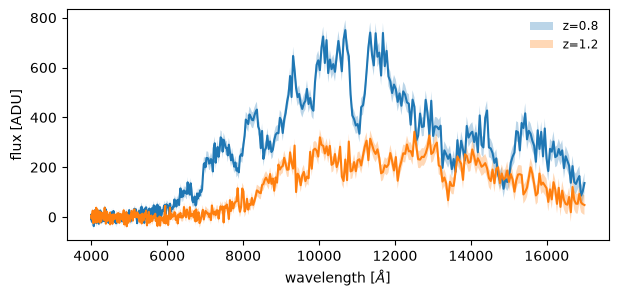

In [5]:
fig, ax = plt.subplots(figsize=[7, 3])
for flux, variance, label in [(flux_1, variance_1, "z=0.8"), (flux_2, variance_2, "z=1.2")]:
    ax.plot(lbda, flux)
    ax.fill_between(lbda, flux - np.sqrt(variance), flux + np.sqrt(variance),
                    alpha=0.3, label=label)

ax.legend(frameon=False, fontsize="small")
ax.set(xlabel=r"wavelength [$\AA$]", ylabel="flux [ADU]")
save(fig, "spectra_examples.png")

## 3. A supernova in its host galaxy

The host is named `"spatial:spectral"`, e.g. `"sersic:bb-5000"` or a real
galaxy such as `"ngc0628"` (see the
[host galaxy tutorial](beginner_host_galaxy.ipynb)). It follows the redshift
of the supernova.

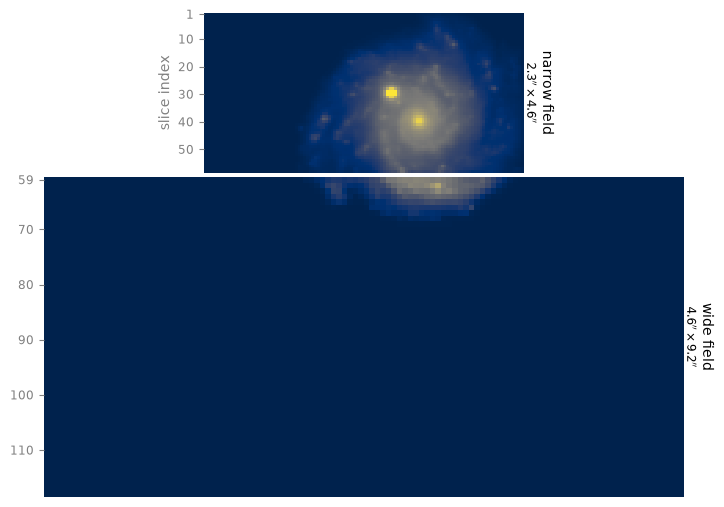

In [6]:
sn = slicersim.LazuliSupernova(redshift=0.9, host="ngc0628")

# positions in spaxels from the field center
sn.change_properties(pointsource__position=[+10, +0], host__position=[+20, -10])

# the narrow and wide field cubes, sky switched off, summed over 4000-7000 Å
(cube_narrow, _), (cube_wide, _) = sn.get_cube(switch_off=["background", "thermal"],
                                               psf_profile="airy")
fig = sn.show_cube((cube_narrow, cube_wide), lbda_range=[4000, 7000])
save(fig, "host_cube.png")

The host is a source of flux and noise in the supernova spectrum. Here, the
supernova sits on a spiral arm, where the host contributes about 1% of the
variance (less than the zodiacal background):

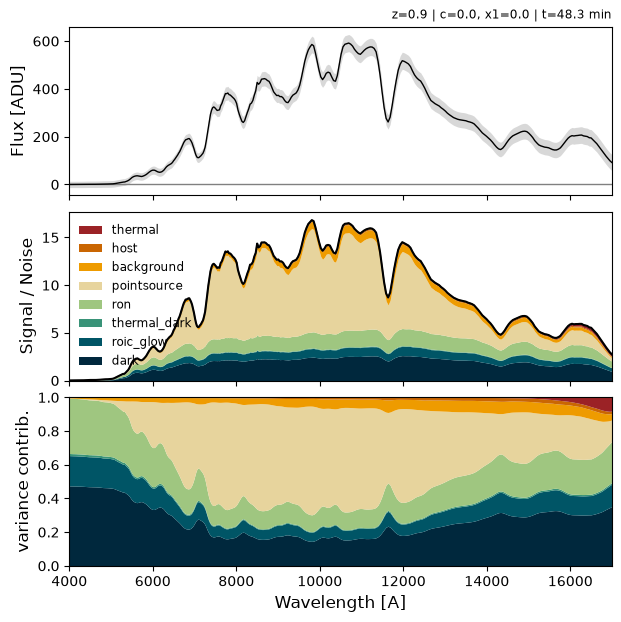

In [7]:
_ = sn.setup_to_snr(20)
fig = sn.simulation.show_variance_sources(flux_calibrated=False)
save(fig, "host_variance.png")

## 4. Going deeper: the `Simulation`

Every target is backed by a `Simulation`, which chains a scene, a telescope,
a spectrograph and a detector.

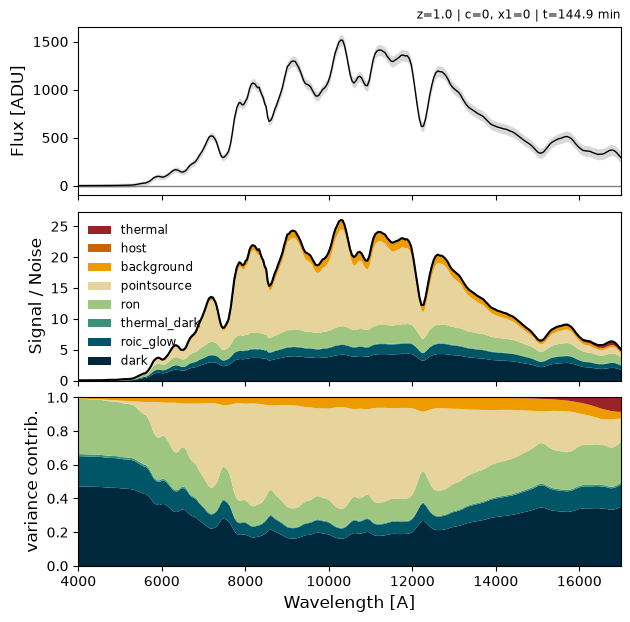

In [8]:
config = slicersim.get_config(instrument="lazuli_cbe.toml")
sim = slicersim.Simulation.from_config(config)

# set the target you want
sim.update(pointsource__redshift=1.0, x1=0, c=0)

# find the read-out mode reaching a mean SNR of 20 in [4000, 6800] Å rest-frame
new_config, snr, exptime = sim.fetch_snr(20, lbda_range=[4000, 6800], frame="rest")
sim.update(**new_config)

# expected spectrum [ADU] and the contribution of each noise source
lbda, flux, variance = sim.get_spectrum()
fig = sim.show_variance_sources(flux_calibrated=False)
save(fig, "spectra_variance.png")

`sim.mutable_parameters` lists everything you can change with `sim.update(...)`.